# PS2 Part 1: Automatic Differentiation

Three problems:

1. **AD by hand.** Compute a small Jacobian with forward mode and with backward mode.
2. **Fuel tank design.** Differentiate a drag model by hand and with PyTorch, then minimize drag with three gradient sources.
3. **Bouncing ball.** Use AD for sensitivity analysis, and find a case where it misleads you.

Fill in the tables directly in the Markdown cells, and answer each **Question** in its **Student Response** line. The notation follows the Taking Derivatives chapter.

In [1]:
import numpy as np
import torch
import matplotlib.pyplot as plt
from scipy import optimize

np.random.seed(42)
torch.manual_seed(42);  # semicolon hides the returned generator object

## Problem 1: Forward and Backward Mode AD by Hand

Consider the function with two inputs and two outputs
$$
\begin{aligned}
f_1(x_1, x_2) &= x_1^2 + \sin(x_2) \\
f_2(x_1, x_2) &= x_1 x_2 + \exp(x_1)
\end{aligned}
$$
at the point $(x_1, x_2) = (2, \pi)$.

**Forward mode.** Break both functions into elementary operations, one per row. The input rows and the first operation are filled in as examples. Add or delete rows if your graph has a different number of nodes. Then fill in each node's value and its tangent $\dot{v}$ for each seed. Seed $[1, 0]$ means $\dot{x}_1 = 1, \dot{x}_2 = 0$.

| Node | Expression | Value | $\dot{v}$, seed $[1, 0]$ | $\dot{v}$, seed $[0, 1]$ |
|---|---|---|---|---|
| $x_1$ | input | 2 | 1 | 0 |
| $x_2$ | input | $\pi$ | 0 | 1 |
| $v_1$ | $x_1^2$ | 4 | 4 | 0 |
| $v_2$ | | | | |
| $v_3$ | | | | |
| $v_4$ | | | | |
| $v_5$ | | | | |
| $v_6$ | | | | |

**Backward mode.** Using the same nodes, fill in the adjoint $\bar{v}$ of each node for each output seed. Seed $\bar{f} = [1, 0]$ means $\bar{f}_1 = 1, \bar{f}_2 = 0$. Start from the outputs and work toward the inputs.

| Node | $\bar{v}$, seed $\bar{f} = [1, 0]$ | $\bar{v}$, seed $\bar{f} = [0, 1]$ |
|---|---|---|
| | | |
| | | |
| | | |
| | | |
| | | |
| | | |
| $x_2$ | | |
| $x_1$ | | |

**Jacobian** (both modes should give the same answer):
$$
J = \begin{bmatrix}
\frac{\partial f_1}{\partial x_1} & \frac{\partial f_1}{\partial x_2} \\
\frac{\partial f_2}{\partial x_1} & \frac{\partial f_2}{\partial x_2}
\end{bmatrix}
= \begin{bmatrix}
\ ? & ? \\
\ ? & ?
\end{bmatrix}
$$

**Question**: Which part of the Jacobian does one forward pass give you, and which part does one backward pass give you? How many passes did each mode need here, and is either mode cheaper for this function?

**Student Response:** [Insert your response here]

## Problem 2: Aircraft External Fuel Tank Design

*Adapted from Martins, J. R. R. A., & Ning, A. (2021). Engineering Design Optimization, Cambridge University Press (page 218, problem 5.11).*

An aircraft carries an external fuel tank shaped like an ellipsoid of revolution. We choose its total length $l$ and maximum diameter $d$, with $l > d$, to carry the required fuel with the least drag. The tank's surface area and volume are
$$
S = \frac{\pi}{2}d^{2}\left(1 + \frac{l}{d\sqrt{1-\frac{d^{2}}{l^{2}}}}\arcsin\left(\sqrt{1-\frac{d^{2}}{l^{2}}}\right)\right),
\qquad
V = \frac{\pi}{6}d^{2}l .
$$
The drag force is $D = \frac{1}{2}\rho U^{2} C_{D} S$, with air density $\rho$ = 0.312 kg/m³, flight speed $U$ = 200 m/s, and drag coefficient
$$
C_D = C_f \left[1 + 1.5\left(\frac{d}{l}\right)^{3/2} + 7\left(\frac{d}{l}\right)^{3}\right], \qquad C_f = 0.0035 .
$$

At a fixed volume, a slender tank has a low drag coefficient but a large surface area. A short, fat tank has the opposite. The best design balances the two.

In [2]:
# Tank model in NumPy. l = total length, d = maximum diameter, both in meters.
RHO, U, C_F = 0.312, 200.0, 0.0035  # air density [kg/m³], flight speed [m/s], skin friction coefficient

def surface_area(l, d):
    if d >= l:  # the formula needs l > d; use a sphere's area instead so the optimizer can recover
        return np.pi * d**2
    s = np.sqrt(1 - (d / l)**2)
    return np.pi / 2 * d**2 * (1 + l / (d * s) * np.arcsin(s))

def volume(l, d):
    return np.pi / 6 * d**2 * l

def drag_coefficient(l, d):
    r = d / l
    return C_F * (1 + 1.5 * r**1.5 + 7 * r**3)

def drag(l, d):
    return 0.5 * RHO * U**2 * drag_coefficient(l, d) * surface_area(l, d)

l_baseline, d_baseline = 2.5, 0.8
print(f"Baseline: C_D = {drag_coefficient(l_baseline, d_baseline):.6f}, "
      f"drag = {drag(l_baseline, d_baseline):.2f} N, volume = {volume(l_baseline, d_baseline):.4f} m³")

Baseline: C_D = 0.005253, drag = 168.29 N, volume = 0.8378 m³


### Part A: Backward Mode by Hand

Compute the gradient of the drag coefficient $C_D$ at the baseline design, $l = 2.5$ m and $d = 0.8$ m, with backward mode. Break $C_D$ into elementary operations, one per row, starting from the ratio $v_1 = d / l$. Fill in the values from top to bottom. Then fill in the adjoints from the bottom up, starting from $\bar{C}_D = 1$. Write a number in each cell, with the formula you used if you like. Add or delete rows if your graph has a different number of nodes.

| Node | Expression | Value | Adjoint |
|---|---|---|---|
| $l$ | input | 2.5 | |
| $d$ | input | 0.8 | |
| $v_1$ | $d / l$ | 0.32 | |
| $v_2$ | | | |
| $v_3$ | | | |
| $v_4$ | | | |
| $v_5$ | | | |
| $v_6$ | | | |
| $C_D$ | | | 1 |

$\dfrac{\partial C_D}{\partial l} =$ ____ per meter $\qquad \dfrac{\partial C_D}{\partial d} =$ ____ per meter

**Question**: What do the signs of the two derivatives mean physically? Per meter of change, which variable affects $C_D$ more? What about per percent of change, and why?

**Student Response:** [Insert your response here]

### Part B: AD with PyTorch

**What you write:** the four `*_torch` functions in the next cell. They should do exactly what the NumPy versions above do, using `torch.sqrt`, `torch.arcsin` and so on.

**Given:** the rest of that cell computes gradients at the baseline design with `torch.autograd.grad(output, x)[0]`. You will use the same pattern in Part C and Problem 3. It prints $\partial C_D / \partial l$ and $\partial C_D / \partial d$ for you to compare with your Part A table. The cell after it times one forward pass, then one forward plus one backward pass.

In [ ]:
# TODO: rewrite the four model functions with torch operations (torch.sqrt, torch.arcsin, ...).
# Mirror the NumPy versions exactly, including the d >= l branch. Use a plain `if`, as in the
# NumPy version: torch.where would compute the square root on both branches and give NaN gradients.
def surface_area_torch(l, d):
    raise NotImplementedError

def volume_torch(l, d):
    raise NotImplementedError

def drag_coefficient_torch(l, d):
    raise NotImplementedError

def drag_torch(l, d):
    raise NotImplementedError

# Gradients at the baseline design, one backward pass per output
x = torch.tensor([l_baseline, d_baseline], dtype=torch.float64, requires_grad=True)
grad_D = torch.autograd.grad(drag_torch(x[0], x[1]), x)[0]
grad_V = torch.autograd.grad(volume_torch(x[0], x[1]), x)[0]
grad_C_D = torch.autograd.grad(drag_coefficient_torch(x[0], x[1]), x)[0]
print(f"dD/dl   = {grad_D[0]:.4f},  dD/dd   = {grad_D[1]:.4f}")
print(f"dV/dl   = {grad_V[0]:.4f},  dV/dd   = {grad_V[1]:.4f}")
print(f"dC_D/dl = {grad_C_D[0]:.6f},  dC_D/dd = {grad_C_D[1]:.6f}   <- compare with your Part A table")

In [ ]:
# Time one forward pass, then one forward pass plus one backward pass
x = torch.tensor([l_baseline, d_baseline], dtype=torch.float64, requires_grad=True)
%timeit drag_torch(x[0], x[1])
%timeit torch.autograd.grad(drag_torch(x[0], x[1]), x)

**Question**: Estimate the time of the backward pass alone by subtracting the two measurements. How many forward passes is it worth? Would that ratio change if the model had 1000 inputs instead of 2, and why?

**Student Response:** [Insert your response here]

### Part C: Constrained Optimization

Minimize drag while carrying at least 0.5 m³ of fuel:
$$
\min_{l,\, d} \; D(l, d) \quad \text{subject to} \quad V(l, d) \geq 0.5 \text{ m}^3, \qquad 0.1 \leq l, d \leq 10 .
$$

SciPy's SLSQP optimizer needs the gradient of the drag and the gradient of the constraint. We compare three ways of getting them: finite differences, PyTorch AD, and SciPy's own estimate.

**What you write:** the four gradient functions at the end of the next cell. Each takes `x = [l, d]` and returns a NumPy array of two numbers.
- `drag_gradient_fd` and `constraint_gradient_fd`: call `finite_difference_gradient` on `drag_wrapper` or `volume_constraint`.
- `drag_gradient_torch` and `constraint_gradient_torch`: turn `x` into a tensor with `requires_grad=True`, evaluate your `drag_torch` or `volume_torch`, and return the gradient as a NumPy array.

**Given:** the two cells after that run the optimizer from 100 random starts with each method, print a summary, and plot the best tank.

*Optional:* replace SciPy's estimate with another method, such as the [complex-step method](https://mdolab.engin.umich.edu/wiki/guide-complex-step-derivative-approximation).

In [5]:
V_REQUIRED = 0.5  # m³

# SciPy works with one array x = [l, d]
def drag_wrapper(x):
    return drag(x[0], x[1])

def volume_constraint(x):  # SciPy requires this to be >= 0
    return volume(x[0], x[1]) - V_REQUIRED

def finite_difference_gradient(func, x, eps=1e-7):
    """Forward differences. Costs len(x) + 1 calls to func."""
    x = np.asarray(x, dtype=float)
    f_x = func(x)
    grad = np.zeros_like(x)
    for i in range(len(x)):
        x_step = x.copy()
        x_step[i] += eps
        grad[i] = (func(x_step) - f_x) / eps
    return grad

# TODO: gradients of drag and of the constraint, by finite differences and by PyTorch AD
def drag_gradient_fd(x):
    raise NotImplementedError

def constraint_gradient_fd(x):
    raise NotImplementedError

def drag_gradient_torch(x):
    raise NotImplementedError

def constraint_gradient_torch(x):
    raise NotImplementedError

In [ ]:
# Run SLSQP from the same 100 random starting designs with each gradient method
starts = np.random.default_rng(0).uniform(0.1, 10.0, size=(100, 2))
bounds = [(0.1, 10.0), (0.1, 10.0)]
methods = {
    "Finite differences": (drag_gradient_fd, constraint_gradient_fd),
    "PyTorch AD": (drag_gradient_torch, constraint_gradient_torch),
    "SciPy estimate": (None, None),  # None: SciPy estimates the gradients itself
}

results = {}  # one row per run: start l, start d, final l, final d, drag, success, nfev, njev
for name, (drag_grad, constraint_grad) in methods.items():
    constraint = {'type': 'ineq', 'fun': volume_constraint, 'jac': constraint_grad}
    rows = []
    for x0 in starts:
        res = optimize.minimize(drag_wrapper, x0, method='SLSQP', jac=drag_grad,
                                constraints=constraint, bounds=bounds, options={'maxiter': 500})
        rows.append([x0[0], x0[1], res.x[0], res.x[1], res.fun, res.success, res.nfev, res.njev])
    results[name] = np.array(rows)

# nfev counts SciPy's calls to drag_wrapper, not the calls inside your gradient functions
best_drag = min(r[r[:, 5] == 1, 4].min() for r in results.values())
for name, r in results.items():
    found_best = np.abs(r[:, 4] - best_drag) < 1e-3 * best_drag
    print(f"{name:<20} found the best design in {found_best.mean():.0%} of runs. "
          f"Median nfev = {np.median(r[:, 6]):.0f}, median njev = {np.median(r[:, 7]):.0f}")

In [ ]:
# Side view of the baseline tank and the best tank found
r = results["PyTorch AD"]
l_best, d_best = r[np.argmin(np.where(r[:, 5] == 1, r[:, 4], np.inf)), 2:4]
theta = np.linspace(0, 2 * np.pi, 100)
plt.figure(figsize=(10, 3))
for l, d, label in [(l_baseline, d_baseline, "baseline"), (l_best, d_best, "optimized")]:
    plt.fill(l / 2 * np.cos(theta), d / 2 * np.sin(theta), alpha=0.4,
             label=f"{label}: l = {l:.2f} m, d = {d:.2f} m, V = {volume(l, d):.2f} m³, D = {drag(l, d):.0f} N")
plt.axis('equal')
plt.xlabel('x, flow direction [m]')
plt.legend(loc='lower center', bbox_to_anchor=(0.5, 1.0))
plt.show()

In [8]:
# Your analysis of `results` here (columns: start l, start d, final l, final d, drag, success, nfev, njev)

**Question**: Compare the three gradient methods.
- Do they find the same best design? Which one used the fewest evaluations of the drag model in total? Count every evaluation, NumPy or PyTorch, including those inside your gradient functions. Count one PyTorch forward plus backward pass as one evaluation.
- Some runs end far from the best design. Using `results`, separate the runs that report failure from those that report success at a poor design. Where did each group start?
- Look at the side view. Why is the optimized tank smaller than the baseline? And why does the optimizer stop at its aspect ratio instead of making the tank even more slender?

*Optional:* if the volume constraint is active, you can write $l$ in terms of $d$ and solve a one-variable problem very accurately. Use it to check the methods' accuracy.

**Student Response:** [Insert your response here]

## Problem 3: Bouncing Ball Sensitivity Analysis

AD makes sensitivity analysis cheap: one backward pass gives the sensitivity of one output to every input. Here the output is the velocity of a bouncing ball, simulated with 1000 explicit Euler steps of $\Delta t$ = 0.01 s. The inputs are gravity $g$ = 10 m/s², the coefficient of restitution $e$ = 0.9 (the fraction of speed kept at each bounce), the initial velocity $v_0$ = 0, and the initial height $h_0$ = 10 m. A conditional in the loop detects each bounce.

The function takes the inputs as one array `[g, e, v0, h0]`, either a NumPy array or a PyTorch tensor.

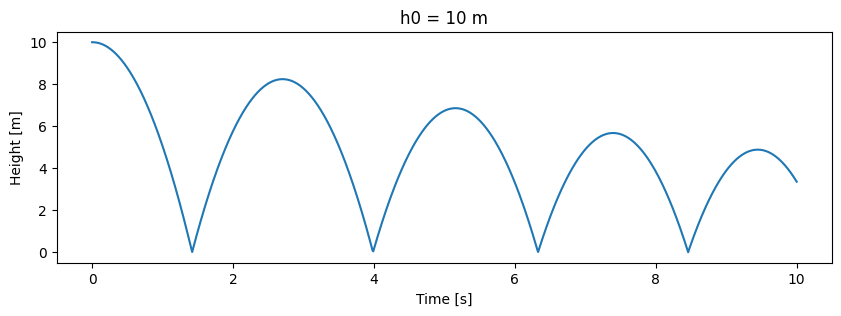

In [9]:
def bounce_simulation(inputs, num_steps=1000, dt=0.01):
    """Bouncing ball with explicit Euler steps. inputs = [g, e, v0, h0], as a NumPy array
    or a torch tensor. Returns the time, height and velocity at every step."""
    g, e, v, h = inputs[0], inputs[1], inputs[2], inputs[3]
    t_tape, h_tape, v_tape = [0.0], [h], [v]
    for i in range(num_steps):
        h = h + v * dt
        v = v - g * dt
        if h <= 0:      # bounce: reflect the part below the floor, reverse and damp the velocity
            h = -h
            v = -e * v
        t_tape.append(t_tape[-1] + dt)
        h_tape.append(h)
        v_tape.append(v)
    return t_tape, h_tape, v_tape

t_tape, h_tape, v_tape = bounce_simulation(np.array([10.0, 0.9, 0.0, 10.0]))
plt.figure(figsize=(10, 3))
plt.plot(t_tape, h_tape)
plt.xlabel('Time [s]')
plt.ylabel('Height [m]')
plt.title('h0 = 10 m')
plt.show()

### Part A: Sensitivity Analysis

We want the sensitivity of the velocity to each input, $\partial v / \partial g$, $\partial v / \partial e$, $\partial v / \partial v_0$ and $\partial v / \partial h_0$, at every time step.

**What you write:** one line in the next cell, marked TODO. It computes the gradient of the velocity at one time step with respect to the four inputs.

**Given:** the loop over time steps and the plots. The cell prints the four sensitivities at $t$ = 10 s for $h_0$ = 10 m and $h_0$ = 1 m. Compare the plots with the height plot above to see what happens at each bounce, then fill in the table below.

In [ ]:
def sensitivities_over_time(h0):
    """Sensitivity of the velocity at every time step to the inputs [g, e, v0, h0]."""
    inputs = torch.tensor([10.0, 0.9, 0.0, h0], dtype=torch.float64, requires_grad=True)
    t_tape, h_tape, v_tape = bounce_simulation(inputs)
    grads = []
    for v_n in v_tape[1:]:
        # TODO: set grad_n to the gradient of v_n with respect to inputs.
        # Use torch.autograd.grad with retain_graph=True, so the graph survives for the next step.
        # It returns a tuple with one gradient per input tensor, so take element [0].
        raise NotImplementedError
        grads.append(grad_n.numpy())
    return np.array(t_tape[1:]), np.array(grads)

# Plot the sensitivities over time for both initial heights (given)
names = ['dv/dg', 'dv/de', 'dv/dv0', 'dv/dh0']
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, h0 in zip(axes, [10.0, 1.0]):
    t, grads = sensitivities_over_time(h0)
    for i in range(4):
        ax.plot(t, grads[:, i], label=names[i])
    ax.set_title(f'Sensitivity of the velocity, h0 = {h0} m')
    ax.set_xlabel('Time [s]')
    ax.legend()
    ax.grid(True, alpha=0.3)
    print(f"h0 = {h0} m, sensitivities at t = 10 s:", np.round(grads[-1], 4))
plt.tight_layout()
plt.show()

Fill in the table from the printed values and the plots. Describe the behavior between and at bounces in a few words, for example "constant" or "flips sign".

| Input | $\partial v / \partial (\cdot)$ at $t$ = 10 s, $h_0$ = 10 m | Between bounces | At a bounce | At $t$ = 10 s, $h_0$ = 1 m |
|---|---|---|---|---|
| $g$ | | | | |
| $e$ | | | | |
| $v_0$ | | | | |
| $h_0$ | | | | |

**Question**: The four sensitivities have different units, so compare each input with itself rather than with the others. How does each sensitivity change between $h_0$ = 10 m and $h_0$ = 1 m, and why? Is the result for $h_0$ physically plausible?

**Student Response:** [Insert your response here]

**Question**: Your code runs one backward pass per time step. How many passes would forward mode need to get the same sensitivities? Which mode is cheaper here, and why? (Problem 1 has the rule.)

**Student Response:** [Insert your response here]

### Part B: Checking AD Against Finite Differences

Part A must run first: this cell reuses `sensitivities_over_time`.

AD says the velocity does not depend on $h_0$ at all. We check that with finite differences: rerun the simulation with $h_0$ nudged up and down by a small step, and divide the change in velocity by the change in $h_0$.

**What you write:** the central-difference estimate in the next cell, marked TODO. It takes about three lines.

**Given:** the cell runs your estimate with a tiny step ($10^{-6}$ m) and a moderate step (0.1 m) and plots both next to the AD result. A third panel plots the final velocity against $h_0$ from 9.95 to 10.05 m.

In [ ]:
h0 = 10.0
t_ad, grads_ad = sensitivities_over_time(h0)  # AD result from Part A
t = np.arange(1001) * 0.01                    # time of every step, including t = 0

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, step in zip(axes[:2], [1e-6, 0.1]):
    # TODO: set fd to the central-difference estimate of dv/dh0 at every time step:
    # run bounce_simulation with h0 + step and with h0 - step, then
    # fd = (velocities_up - velocities_down) / (2 * step), as NumPy arrays.
    raise NotImplementedError
    ax.plot(t, fd, label=f'finite difference, step = {step:g} m')
    ax.plot(t_ad, grads_ad[:, 3], 'k--', label='AD')
    ax.set_ylim(-3, 3)  # zoom in; very large values run off the plot
    ax.set_title(f'dv/dh0, step = {step:g} m')
    ax.set_xlabel('Time [s]')
    ax.legend(loc='lower left')
    ax.grid(True, alpha=0.3)

# Final velocity against h0 over a narrow range (given)
h0_values = np.linspace(9.95, 10.05, 1001)
v_final = [bounce_simulation(np.array([10.0, 0.9, 0.0, h]))[2][-1] for h in h0_values]
axes[2].plot(h0_values, v_final, '.', markersize=2)
axes[2].set_title('Final velocity against h0')
axes[2].set_xlabel('Initial height h0 [m]')
axes[2].set_ylabel('Final velocity [m/s]')
axes[2].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

**Question**: Do AD and finite differences agree, and does the answer depend on the step size? Use your plot of final velocity against $h_0$ to explain why. How would you change the simulation so that AD gives a useful sensitivity to $h_0$? You only need to describe the fix.

**Student Response:** [Insert your response here]